<a href="https://colab.research.google.com/github/alameenShameer/Team3_Horror_Movies_Preprocessing/blob/eda-al-ameen/Team3_Horror_Movies_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Horror Movies Dataset — Complete Data Preprocessing & EDA Workflow

**Team:** Al Ameen · Nikhil · Devika · Vyas · Felicia  
**Dataset:** `horror_movies.csv`  
**Purpose:** Exploratory data analysis and preparation of a supervised regression dataset.

## Team task allocation

| Member | Responsibility |
|---|---|
| **Al Ameen** | Dataset loading, inspection and EDA |
| **Nikhil** | Data cleaning and feature engineering |
| **Devika** | Distribution and categorical analysis; target/leakage review |
| **Vyas** | Split and numerical/categorical preprocessing |
| **Felicia** | Target review, imbalance applicability, correlation, feature selection and verification |

## Prediction objective

**Target column: `vote_average`**

The task is to predict a movie's average audience rating (`vote_average`). This is a **regression problem** because the target is numeric and continuous-like, not a class label.



## 1. Import Libraries
**Owner: Al Ameen**


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 100)
sns.set_theme(style="whitegrid")

## 2. Dataset Loading
**Owner: Al Ameen**

Upload `horror_movies.csv` to the Colab session, or place it in the same folder as this notebook.

In [ ]:

DATA_PATH = '/content/horror_movies.csv'
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())

Shape: (32540, 20)


,id,original_title,title,original_language,overview,tagline,release_date,poster_path,popularity,vote_count,vote_average,budget,revenue,runtime,status,adult,backdrop_path,genre_names,collection,collection_name
0,760161,Orphan: First Kill,Orphan: First Kill,en,"After escaping from an Estonian psychiatric facility, Leena Klammer travels to America by impers...",There's always been something wrong with Esther.,2022-07-27,/pHkKbIRoCe7zIFvqan9LFSaQAde.jpg,5088.584,902,6.9,0,9572765,99,Released,False,/5GA3vV1aWWHTSDO5eno8V5zDo8r.jpg,"Horror, Thriller",760193.0,Orphan Collection
1,760741,Beast,Beast,en,A recently widowed man and his two teenage daughters travel to a game reserve in South Africa. H...,Fight for family.,2022-08-11,/xIGr7UHsKf0URWmyyd5qFMAq4d8.jpg,2172.338,584,7.1,0,56000000,93,Released,False,/2k9tBql5GYH328Krj66tDT9LtFZ.jpg,"Adventure, Drama, Horror",NaN,NaN
2,882598,Smile,Smile,en,"After witnessing a bizarre, traumatic incident involving a patient, Dr. Rose Cotter starts exper...","Once you see it, it’s too late.",2022-09-23,/hiaeZKzwsk4y4atFhmncO5KRxeT.jpg,1863.628,114,6.8,17000000,45000000,115,Released,False,/mVNPfpydornVe4H4UCIk7WevWjf.jpg,"Horror, Mystery, Thriller",NaN,NaN
3,756999,The Black Phone,The Black Phone,en,"Finney Blake, a shy but clever 13-year-old boy, is abducted by a sadistic killer and trapped in ...",Never talk to strangers.,2022-06-22,/lr11mCT85T1JanlgjMuhs9nMht4.jpg,1071.398,2736,7.9,18800000,161000000,103,Released,False,/AfvIjhDu9p64jKcmohS4hsPG95Q.jpg,"Horror, Thriller",NaN,NaN
4,772450,Presencias,Presences,es,"A man who loses his wife and goes to seclude himself in a cabin in the woods, where strange thin...",NaN,2022-09-07,/dgDT3uol3mdvwEg0jt1ble3l9hw.jpg,1020.995,83,7.0,0,0,0,Released,False,/ojfzhdwRemcDt1I6pao6vVLw9AA.jpg,Horror,NaN,NaN


## 3. Initial Data Inspection
**Owner: Al Ameen**

Inspect shape, columns, data types, descriptive statistics, missing values, duplicates and distinct values. This establishes the baseline before modifying the data.

In [ ]:
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nNumerical summary:")
display(df.describe().T)

print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

print("\nExact duplicate rows:", df.duplicated().sum())

print("\nDistinct values per column:")
display(df.nunique(dropna=False).sort_values().to_frame("unique_count"))

Rows and columns: (32540, 20)

Column names:
['id', 'original_title', 'title', 'original_language', 'overview', 'tagline', 'release_date', 'poster_path', 'popularity', 'vote_count', 'vote_average', 'budget', 'revenue', 'runtime', 'status', 'adult', 'backdrop_path', 'genre_names', 'collection', 'collection_name']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32540 entries, 0 to 32539
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 32540 non-null  int64  
 1   original_title     32540 non-null  object 
 2   title              32540 non-null  object 
 3   original_language  32540 non-null  object 
 4   overview           31254 non-null  object 
 5   tagline            12706 non-null  object 
 6   release_date       32540 non-null  object 
 7   poster_path        28066 non-null  object 
 8   popularity         32540 non-null  float64
 9   vote_count 

,count,mean,std,min,25%,50%,75%,max
id,32540.0,4.459108e+05,3.057447e+05,17.0,146494.75,426521.00,707534.00000,1.033095e+06
popularity,32540.0,4.013456e+00,3.751347e+01,0.0,0.60,0.84,2.24325,5.088584e+03
vote_count,32540.0,6.269149e+01,4.208875e+02,0.0,0.00,2.00,11.00000,1.690000e+04
vote_average,32540.0,3.335728e+00,2.876002e+00,0.0,0.00,4.00,5.70000,1.000000e+01
budget,32540.0,5.431266e+05,4.542668e+06,0.0,0.00,0.00,0.00000,2.000000e+08
revenue,32540.0,1.349747e+06,1.443048e+07,0.0,0.00,0.00,0.00000,7.018426e+08
runtime,32540.0,6.214290e+01,4.099853e+01,0.0,14.00,80.00,91.00000,6.830000e+02
collection,2306.0,4.815349e+05,3.244982e+05,656.0,155421.00,471259.00,759067.25000,1.033032e+06



Missing values:


,missing_count
collection,30234
collection_name,30234
tagline,19834
backdrop_path,18995
poster_path,4474
overview,1286
original_title,0
id,0
original_language,0
title,0



Exact duplicate rows: 0

Distinct values per column:


,unique_count
adult,1
status,4
vote_average,92
original_language,97
runtime,212
genre_names,772
budget,783
collection,816
collection_name,816
vote_count,1105


### Initial observations

- The dataset contains movie metadata, financial fields, popularity/voting measures, release dates, genre strings and image-path fields.
- `overview`, `tagline`, `poster_path`, `backdrop_path`, `collection` and `collection_name` contain missing values.
- `budget`, `revenue` and some `runtime` values may use zero as an unknown/not-recorded placeholder; zero should be reviewed rather than assumed to be a genuine measurement.
- `vote_average` is the selected numeric prediction target for the regression task; inspect its distribution and missing values.

## 4. Exploratory Data Analysis (EDA) — Data Visualization
**Owner: Al Ameen**

Explore numerical distributions, movie release years, language, status, genre frequency, rating and financial fields. These plots describe the raw data; they do not imply causation.

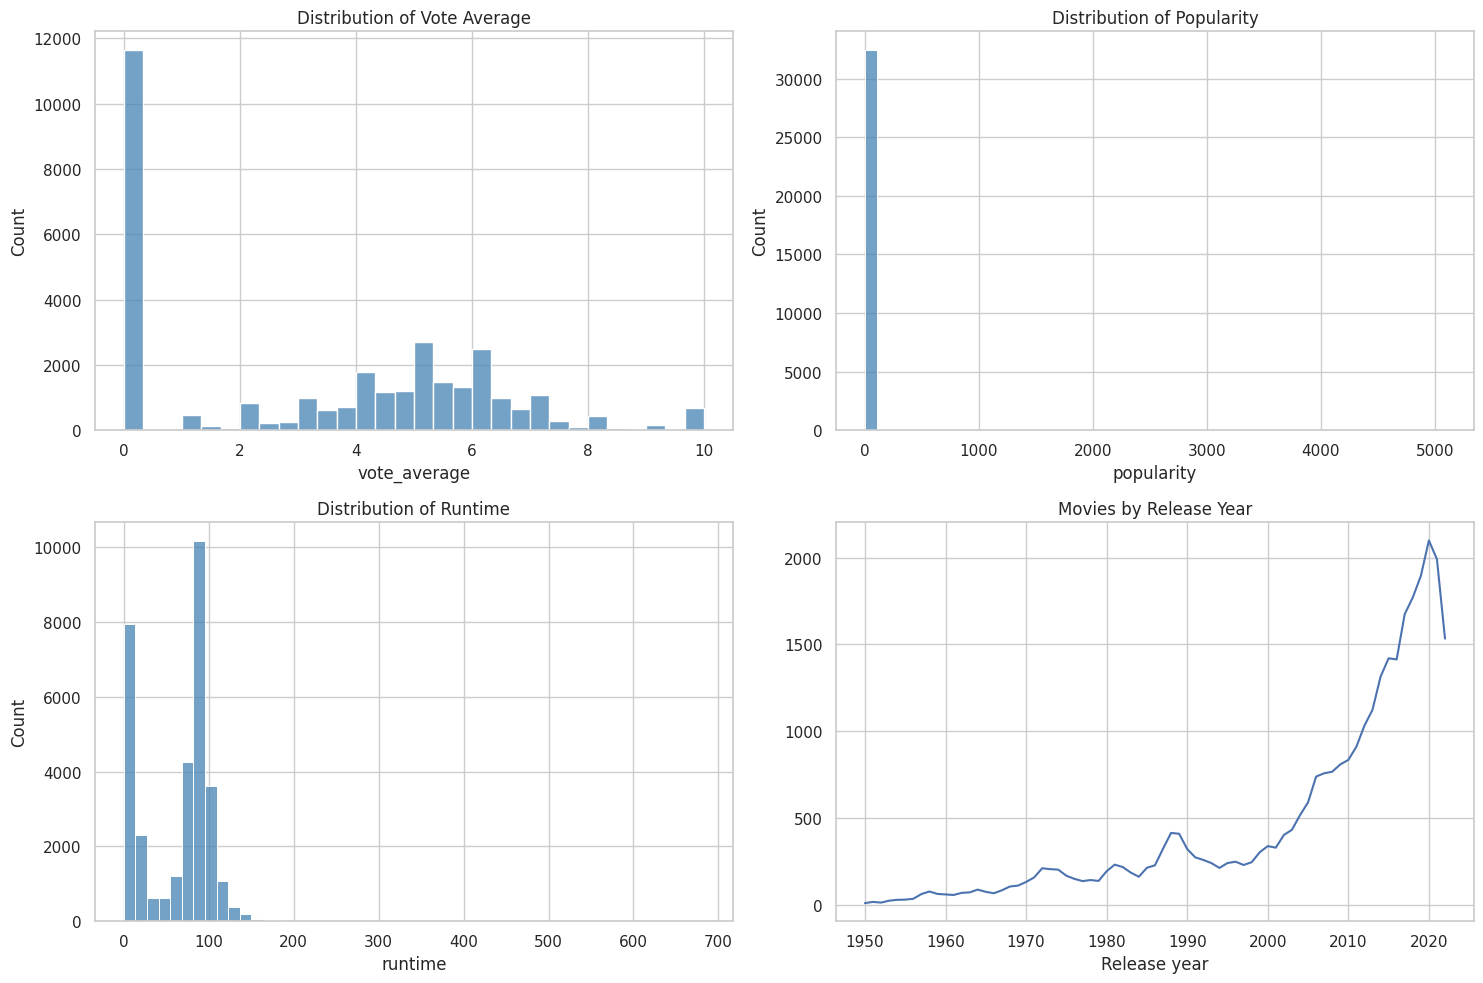

In [ ]:
# Parse dates for visualization without changing the original column yet.
eda_dates = pd.to_datetime(df["release_date"], errors="coerce")
release_year = eda_dates.dt.year

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.histplot(df["vote_average"], bins=30, kde=False, color="steelblue", ax=axes[0, 0])
axes[0, 0].set_title("Distribution of Vote Average")
sns.histplot(df["popularity"], bins=50, kde=False, color="steelblue", ax=axes[0, 1])
axes[0, 1].set_title("Distribution of Popularity")
sns.histplot(df["runtime"], bins=50, kde=False, color="steelblue", ax=axes[1, 0])
axes[1, 0].set_title("Distribution of Runtime")
release_year.dropna().astype(int).value_counts().sort_index().plot(ax=axes[1, 1])
axes[1, 1].set_title("Movies by Release Year")
axes[1, 1].set_xlabel("Release year")
plt.tight_layout()
plt.show()

1. Numerical data analysis

Plot 1: Distribution of Vote Average
Observations:
- A large number of movies have a vote_average of 0.
- Most movies with non-zero ratings are concentrated between approximately 4 and 7.
- The distribution is not uniform, indicating differences in movie ratings.
- The large number of zero ratings should be investigated because they may represent movies without sufficient audience votes.
Important: Since vote_average is your target column, investigate whether zero represents a genuine rating or an absence of ratings before model training.

Plot 2: Distribution of Popularity
Observations:
- The distribution is highly right-skewed.
- Most movies have relatively low popularity values.
- A small number of movies have extremely high popularity values.
- These extreme values create a long right tail, indicating the presence of potential outliers.


Plot 3: Distribution of Runtime
Observations:
- Most movies have runtimes concentrated approximately between 70 and 110 minutes.
- A considerable number of records have a runtime of zero.
- Some movies have unusually high runtime values.
- The distribution is not normal and contains potential outliers.
Important: Runtime values of zero should be investigated because they may represent missing or unrecorded information.


Plot 4: Movies by Release Year
Observations:
- The number of movies generally increases over the years.
- There is a noticeable increase in movie records after the 2000s.
- The highest number of records appears around 2020.
- A decline is visible in the most recent years, which may be due to incomplete dataset coverage.

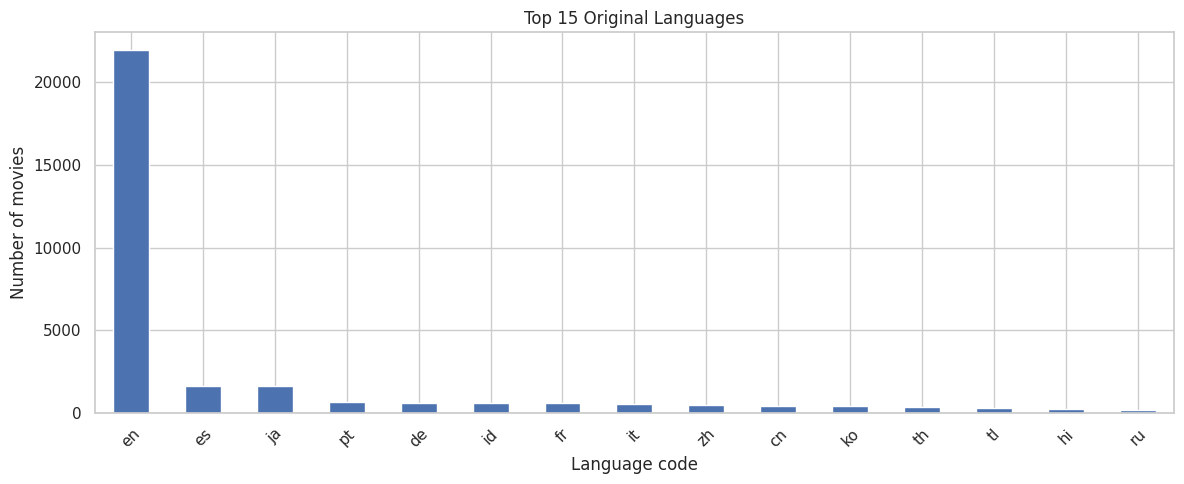

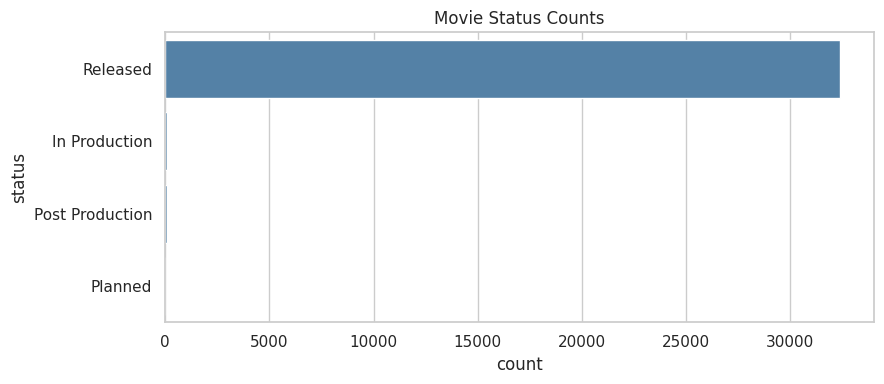

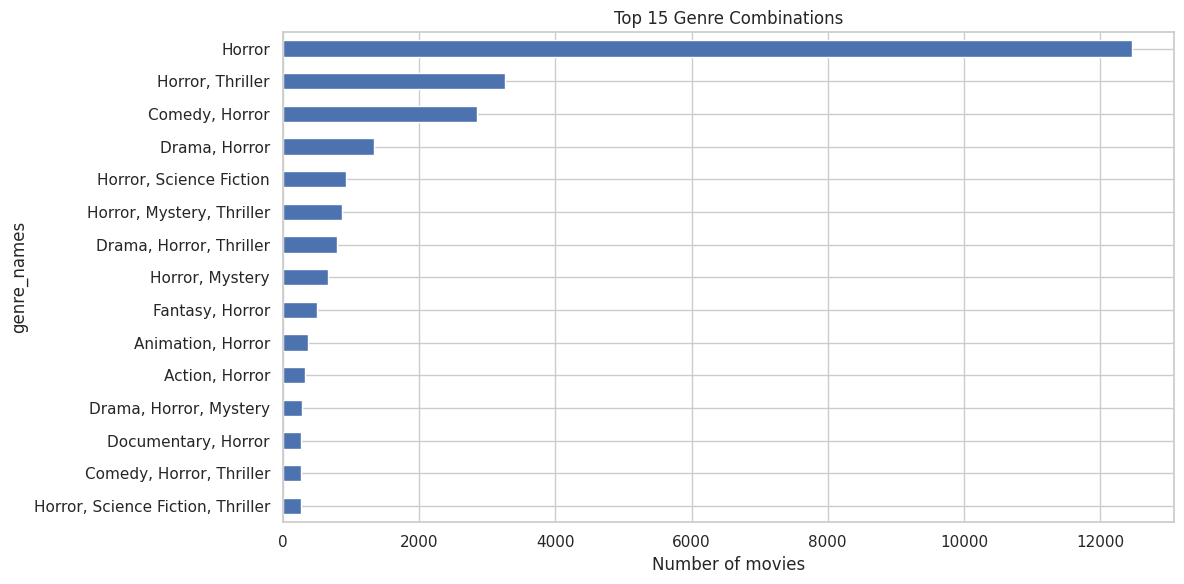

In [ ]:
# Top 15 original languages
plt.figure(figsize=(12, 5))
df["original_language"].value_counts().head(15).plot(kind="bar")
plt.title("Top 15 Original Languages")
plt.xlabel("Language code")
plt.ylabel("Number of movies")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Movie status distribution
plt.figure(figsize=(9, 4))
sns.countplot(data=df, y="status", order=df["status"].value_counts().index, color="steelblue")
plt.title("Movie Status Counts")
plt.tight_layout()
plt.show()

# Most common genre combinations
plt.figure(figsize=(12, 6))
df["genre_names"].value_counts().head(15).sort_values().plot(kind="barh")
plt.title("Top 15 Genre Combinations")
plt.xlabel("Number of movies")
plt.tight_layout()
plt.show()

2. Categorical data analysis

Plot 5: Top 15 Original Languages
Observations:
- English (en) is the dominant original language in the dataset.
- Spanish (es) and Japanese (ja) are the next most frequently represented languages.
- Other languages have considerably fewer movie records.
- The dataset has an imbalanced distribution of movies across original languages.

Plot 6: Movie Status Distribution
Observations:
- The majority of movies have a status of Released.
- Very few movies belong to In Production, Post Production and Planned categories.
- The status distribution is highly imbalanced.
- Most records represent movies that have already been released.

Plot 7: Top 15 Genre Combinations
Observations:
- Horror is the most frequently occurring genre combination.
- Horror and Thriller is the second most common combination.
- Comedy and Horror is another frequently occurring combination.
- Horror appears in almost all the most frequent genre combinations.
- Genre combinations vary in frequency, indicating differences in genre representation.

### Overall EDA Conclusion

- The dataset contains 32,540 movie records and 20 columns.
- The target variable `vote_average` contains a considerable number of zero values that require further investigation.
- Popularity and runtime distributions show skewness and potential outliers.
- English is the most dominant original language.
- Most movies belong to the Released status.
- Horror is the most frequently occurring genre, followed by Horror-Thriller combinations.
- Movie records have generally increased over the years, with a noticeable peak around 2020.
- Missing values, zero placeholders, outliers and categorical distributions need to be considered during data preprocessing.

Overall, the EDA provides an understanding of the dataset's structure, distributions and potential data quality issues before proceeding with data cleaning and feature engineering.